In [22]:
# CHATGPT ILLUSTRATION

import numpy as np
from scipy.stats import norm, beta
import matplotlib.pyplot as plt
from ot import sliced_wasserstein_distance


def generate_reference(n_samples=20000, rho=-0.5, random_state=0):
    """
    Generate a reference dataset with Beta-like marginals and
    a target Gaussian-copula correlation.

    Parameters
    ----------
    n_samples : int
        Number of samples to generate.
    rho : float
        Target linear correlation between wind and solar in the copula.
    random_state : int
        Seed for the random number generator.

    Returns
    -------
    np.ndarray
        Array of shape (n_samples, 2) with columns (wind, solar).
    """
    rng = np.random.default_rng(random_state)
    cov = np.array([[1.0, rho], [rho, 1.0]])

    z = rng.multivariate_normal(
        mean=[0.0, 0.0],
        cov=cov,
        size=n_samples,
    )

    u = norm.cdf(z)
    wind = beta(2.0, 5.0).ppf(u[:, 0])
    solar = beta(2.0, 2.0).ppf(u[:, 1])

    return np.column_stack((wind, solar))


def permute_to_target_corr(
    wind_sorted,
    solar_sorted,
    target_corr,
    max_iter=10000,
    tol=0.02,
    random_state=None,
):
    """
    Permute solar_sorted so that its correlation with wind_sorted is
    close to target_corr, while preserving the marginals.

    Parameters
    ----------
    wind_sorted : np.ndarray
        Sorted wind values (n_samples,).
    solar_sorted : np.ndarray
        Sorted solar values (n_samples,).
    target_corr : float
        Desired Pearson correlation coefficient.
    max_iter : int
        Maximum number of swap proposals.
    tol : float
        Target tolerance for the correlation.
    random_state : int | None
        Seed for the random number generator.

    Returns
    -------
    np.ndarray
        Permuted solar values.
    float
        Achieved correlation.
    """
    rng = np.random.default_rng(random_state)
    if target_corr >= 0.0:
        solar_perm = solar_sorted.copy()
    else:
        solar_perm = solar_sorted[::-1].copy()

    current_corr = np.corrcoef(wind_sorted, solar_perm)[0, 1]

    for _ in range(max_iter):
        if abs(current_corr - target_corr) <= tol:
            break

        i, j = rng.integers(0, wind_sorted.size, size=2)
        if i == j:
            continue

        solar_perm[i], solar_perm[j] = solar_perm[j], solar_perm[i]
        new_corr = np.corrcoef(wind_sorted, solar_perm)[0, 1]

        if abs(new_corr - target_corr) < abs(current_corr - target_corr):
            current_corr = new_corr
        else:
            solar_perm[i], solar_perm[j] = solar_perm[j], solar_perm[i]

    return solar_perm, current_corr


def build_correlated_variants(reference):
    """
    Build two datasets from the reference that have the same marginals
    but different dependence structures (around +0.5 and -0.5).

    Parameters
    ----------
    reference : np.ndarray
        Reference samples of shape (n_samples, 2)
        with columns (wind, solar).

    Returns
    -------
    dict
        Dictionary with keys 'anti' and 'positive'.
    """
    wind_ref = reference[:, 0]
    solar_ref = reference[:, 1]

    wind_sorted = np.sort(wind_ref)
    solar_sorted = np.sort(solar_ref)

    solar_pos, corr_pos = permute_to_target_corr(
        wind_sorted,
        solar_sorted,
        target_corr=0.5,
        random_state=1,
    )
    solar_anti, corr_anti = permute_to_target_corr(
        wind_sorted,
        solar_sorted,
        target_corr=-0.5,
        random_state=2,
    )

    positive = np.column_stack((wind_sorted, solar_pos))
    anti = np.column_stack((wind_sorted, solar_anti))

    print(f"Target +0.5, achieved: {corr_pos:.3f}")
    print(f"Target -0.5, achieved: {corr_anti:.3f}")

    return {"anti": anti, "positive": positive}


def print_correlations(datasets):
    """
    Print sample correlations for each dataset.

    Parameters
    ----------
    datasets : dict
        Mapping from dataset name to array of shape (n_samples, 2).
    """
    for name, data in datasets.items():
        corr = np.corrcoef(data.T)[0, 1]
        print(f"{name}: corr(wind, solar) = {corr:.3f}")


def check_marginals_equal(reference, other, other_name):
    """
    Check if the marginals of another dataset match the reference.

    Parameters
    ----------
    reference : np.ndarray
        Reference dataset of shape (n_samples, 2).
    other : np.ndarray
        Other dataset of shape (n_samples, 2).
    other_name : str
        Name of the other dataset, for printing.
    """
    wind_equal = np.allclose(
        np.sort(reference[:, 0]),
        np.sort(other[:, 0]),
    )
    solar_equal = np.allclose(
        np.sort(reference[:, 1]),
        np.sort(other[:, 1]),
    )
    print(
        f"{other_name}: wind marginals equal to reference: {wind_equal}, "
        f"solar marginals equal to reference: {solar_equal}",
    )


def plot_marginals(datasets, bins=40):
    """
    Plot marginal histograms of wind and solar for each dataset.

    Parameters
    ----------
    datasets : dict
        Mapping from dataset name to array of shape (n_samples, 2).
    bins : int
        Number of bins for the histograms.
    """
    n_sets = len(datasets)
    fig, axes = plt.subplots(
        2,
        n_sets,
        figsize=(4 * n_sets, 6),
        sharex="row",
        sharey="row",
    )

    if n_sets == 1:
        axes = np.array([[axes[0]], [axes[1]]])

    for col, (name, data) in enumerate(datasets.items()):
        wind = data[:, 0]
        solar = data[:, 1]

        axes[0, col].hist(
            wind,
            bins=bins,
            density=True,
            alpha=0.6,
            label=name,
        )
        axes[0, col].set_title(f"{name} - wind")
        axes[0, col].set_xlabel("wind")
        axes[0, col].set_ylabel("pdf")

        axes[1, col].hist(
            solar,
            bins=bins,
            density=True,
            alpha=0.6,
            label=name,
        )
        axes[1, col].set_title(f"{name} - solar")
        axes[1, col].set_xlabel("solar")
        axes[1, col].set_ylabel("pdf")

    plt.tight_layout()
    plt.show()

Target +0.5, achieved: 0.519
Target -0.5, achieved: -0.520
reference: corr(wind, solar) = -0.198
anti: corr(wind, solar) = -0.520
positive: corr(wind, solar) = 0.519
anti: wind marginals equal to reference: True, solar marginals equal to reference: True
positive: wind marginals equal to reference: True, solar marginals equal to reference: True


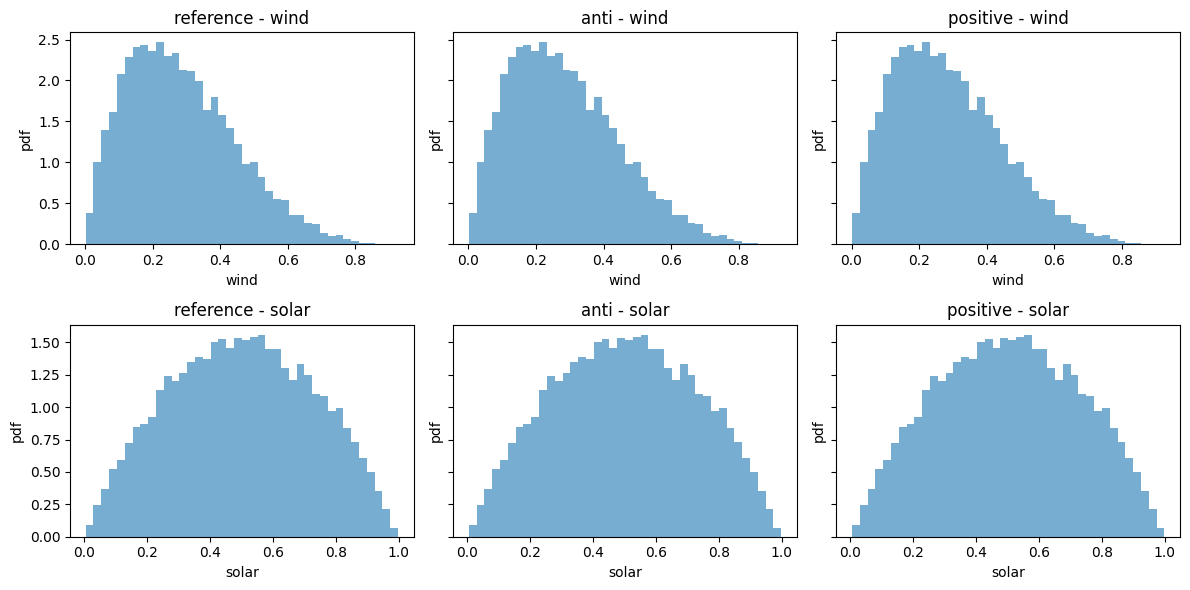

In [23]:
# 1) Reference with slight anti-correlation (~ -0.2)
reference = generate_reference(n_samples=20000, rho=-0.2, random_state=0)

# 2) Build two variants with same marginals but very different dependence
variants = build_correlated_variants(reference)

datasets = {
    "reference": reference,
    "anti": variants["anti"],
    "positive": variants["positive"],
}

print_correlations(datasets)
check_marginals_equal(reference, variants["anti"], "anti")
check_marginals_equal(reference, variants["positive"], "positive")

plot_marginals(datasets)

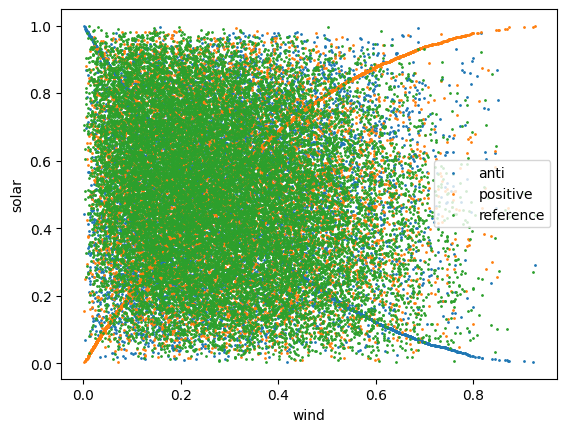

In [24]:
plt.scatter(
    datasets["anti"][:, 0],
    datasets["anti"][:, 1],
    s=1,
    label="anti",
)
plt.scatter(
    datasets["positive"][:, 0],
    datasets["positive"][:, 1],
    s=1,
    label="positive",
)
plt.scatter(
    datasets["reference"][:, 0],
    datasets["reference"][:, 1],
    s=1,
    label="reference",
)
plt.xlabel("wind")
plt.ylabel("solar")
plt.legend()

In [ ]:
# here you see that the three datasets have identical marginals, but different joint distributions
# hence, different SWD-scores. Anti vs reference is closer, because their correlations are similar.
swd_anti = sliced_wasserstein_distance(
    datasets["anti"], datasets["reference"], n_projections=100
)
swd_positive = sliced_wasserstein_distance(
    datasets["positive"], datasets["reference"], n_projections=100
)
swd_ref = sliced_wasserstein_distance(
    datasets["reference"], datasets["reference"], n_projections=100
)
print(
    f"Sliced Wasserstein Distances:\n"
    f"  anti vs reference: {swd_anti:.4f}\n"
    f"  positive vs reference: {swd_positive:.4f}\n"
    f"  reference vs reference: {swd_ref:.4f}"
)

Sliced Wasserstein Distances:
  anti vs reference: 0.0307
  positive vs reference: 0.0535
  reference vs reference: 0.0000
